<!-- The badge's branch and the setup cell's `git clone -b` must name the same branch. -->

> **Recommended: run this notebook in Google Colab, nothing to install.**
>
> [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/dev/docs/notebooks/notebook_3/notebook_3.ipynb)
>
> The notebook opens with the results of an earlier run. To start from a clean notebook, choose Edit → Clear all outputs in Colab's menu first.
>
> Click the ▶ button on each cell (or press Shift+Enter) to see the results and move on to the next one.
>
> If you can't or don't want to use Colab, the documentation website shows the pre-run results.

# Session 3: How a Navigate model is built

> **Disclaimer**
>
> Navigate is an open-source analytical model intended for research and scenario analysis of maritime decarbonisation pathways. The model, its assumptions and any outputs are provided for illustrative and analytical purposes only.
>
> Model outputs depend on the assumptions selected by the user and should not be interpreted as forecasts, benchmarks, recommendations or commercially optimal outcomes, nor as legal, financial or investment advice.
>
> Users are responsible for selecting and adapting assumptions appropriate to their own circumstances and for exercising their own independent judgement when interpreting or relying on any model outputs.

To have a full understanding of Navigate's structure and language, we recommend working through the [Tutorials](https://zerocarbonshipping.github.io/navigate-zcs/tutorials/index.html) and having a look at the [Reference Manual](https://zerocarbonshipping.github.io/navigate-zcs/reference_manual/index.html) before starting this session.

This session shows how the deck is built and the data behind it, using the case of [Session 1](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/dev/docs/notebooks/notebook_1/notebook_1.ipynb) (the copper trade) or of [Session 2](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/dev/docs/notebooks/notebook_2/notebook_2.ipynb) (the global case) as an illustration. [Session 4](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/workshop-colab/docs/workshop/04-how-navigate-solves.ipynb) shows how the model solves it step by step, and its results in detail.

## What you'll do

**Pick the case.** The copper trade of Session 1 or the global case of Session 2.

**Build the simulation.** See how a case like this is expressed using Navigate's library of components.

**Explore the input data.** Look at the numerical assumptions that will drive the answer.

## STEP 1: Setup

Run the cell below on Colab or [locally](https://zerocarbonshipping.github.io/navigate-zcs/staging/notebooks/index.html#running-a-notebook-on-your-own-machine) to set up the Navigate model.

In [1]:
ROOT = "/content"
# running locally: ROOT = any folder of your own, without spaces in its path, e.g. "/tmp/notebook"
%cd {ROOT}

import os
import shutil
import stat
# a copy from an earlier run goes, so the clone below is the current version (git's read-only files too)
if os.path.exists(f"{ROOT}/navigate-zcs"):
    shutil.rmtree(f"{ROOT}/navigate-zcs", onexc=lambda remove, path, _: (os.chmod(path, stat.S_IWRITE), remove(path)))
!git clone -q --depth 1 -b dev https://github.com/zerocarbonshipping/navigate-zcs {ROOT}/navigate-zcs
%pip install -q {ROOT}/navigate-zcs \
    git+https://github.com/zerocarbonshipping/lantern-zcs@dev
%env ASSUMPTIONS_DATA_DIR={ROOT}/navigate-zcs/assumptions

# the cells below read the cases and the library from the clone, by their paths in the repository
%cd {ROOT}/navigate-zcs

# the tools the cells below call ----------------------------------------------------------------------
import contextlib
import html
import io
import json
import logging
import re
import time
import uuid
from importlib import resources
from pathlib import Path

import dataclasses

import lantern.config
import lantern.figures
import numpy as np
import pandas as pd
import polars as pl
import plotly.graph_objects as go
import yaml
from IPython.display import HTML, Markdown, display
from plotly.subplots import make_subplots

from navigate.core.enum_ import PolicyScopeID, RegulationMeasureID
from navigate.parser import Parser
from navigate.simulation.time_stepping import Simulation
from navigate.util import dates_to_years

# the two cases this session can explain: Notebook 1's copper trade, and the scenario Notebook 2's global case
# starts from, the Center's basecase with mid regulation, from Notebook 2's own folder and read year by year
CASES = {
    "notebook_1": {"deck": "docs/notebooks/notebook_1/copper_trade/example_4.nav",
                   "notebook": "docs/notebooks/notebook_1/notebook_1.ipynb", "params": {}},
    "notebook_2": {"deck": "docs/notebooks/notebook_2/global_case/basecase_mid_regulation.nav",
                   "notebook": "docs/notebooks/notebook_2/notebook_2.ipynb", "params": {"GRID": "yearly"}},
}
LIBRARY = Path("assumptions/defaults")
MODULES = Path("assumptions/modules")

case = {}  # the case read last: its deck, its nodes after the first year, and the fleet the figures follow


def read_case(name):
    # show the case's map, read its deck and solve its first year: the regulations' emission factors are worked out
    # at the start of a year, so the regulation figures read them from there; nothing else in this session is a result
    assert name in CASES, f"choose CASE from {list(CASES)}"
    spec = CASES[name]
    show_map(spec["notebook"])

    started = time.time()
    parser = Parser()
    logging.getLogger("navigate").setLevel(logging.ERROR)  # without the notes on library nodes the deck leaves unused
    parser.read_deck(Path(spec["deck"]).resolve(), data_dir=Path("assumptions").resolve(), params=spec["params"])
    nodes = parser.nodes
    simulation = Simulation(nodes, parser.general_nodes, parser.dates, Path("first_year_infeasible.lp"))
    simulation.initialize()
    with contextlib.redirect_stdout(io.StringIO()):  # without the solver's banner
        simulation.step(parser.read_events(parser.dates[0]))

    start = parser.general_nodes.model_definition.start_date
    # the dates from the start date to the end of 2050 a forecast is drawn at, and each in the years since the
    # start date that Navigate reads a forecast at
    dates = start + np.linspace(0, (np.datetime64("2050-12-31") - start).astype(int), 300).astype("timedelta64[D]")
    case.update(name=name, deck=Path(spec["deck"]), params=spec["params"], nodes=nodes, start=start,
                lifetime=parser.general_nodes.model_definition.emissions_lifetime,
                dates=dates, years=dates_to_years(dates, start))
    counts = ", ".join(f"{len(getattr(nodes, kind))} {kind if len(getattr(nodes, kind)) != 1 else kind[:-1]}"
                       for kind in ("fleets", "vessels", "fuels", "plants", "ports", "regulations"))
    print(f"Read {case['deck'].name} and solved its first year in {time.time() - started:.0f} s: {counts}.")
    print(f"The case's own files are in navigate-zcs/{case['deck'].parent.as_posix()}/, the library in "
          f"navigate-zcs/assumptions/.")


def show_map(notebook):
    # the case's map and its caption, as the case's own notebook shows them
    cells = ["".join(cell["source"]) for cell in json.loads(Path(notebook).read_text("utf-8"))["cells"]]
    at = next(i for i, cell in enumerate(cells) if cell.startswith("![Map"))
    caption = cells[at + 1].split("\n\n")[0]
    display(Markdown(cells[at] + "\n\n" + caption))


# ---- the deck's files ----------------------------------------------------------------------------------------

DECK_TABS = {
    "notebook_1": lambda folder: {
        "example_4.nav": [folder / "example_4.nav"],
        "Fleet": [folder / "includes/fleet.inc", LIBRARY / "Fleet/bulk_carrier_80k_dwt.inc"],
        "Route": [folder / "includes/route.inc", folder / "includes/ports.inc"],
        "Fuel": [folder / "includes/fuel_production.inc", folder / "includes/regions.inc",
                 folder / "includes/producer.inc"] + delivery_files(),
        "Regulation": [folder / "includes/eu_ets.inc", folder / "includes/fuel_eu.inc"],
        "Behavioural traits": [MODULES / "default_calibration.inc"],
        "Events": [MODULES / "default_time_step_yearly.inc"],
    },
    "notebook_2": lambda folder: {
        "basecase_mid_regulation.nav": [folder / "basecase_mid_regulation.nav"],
        "Fleet": [MODULES / "default_fleet.inc"],
        "Route": [MODULES / "default_port.inc"],
        "Fuel": [MODULES / "default_fuel.inc", MODULES / "default_producer.inc", MODULES / "default_feedstock.inc",
                 "Also: default_region.inc, default_plant.inc, default_source.inc and default_transport.inc, "
                 "in assumptions/modules/"],
        "Regulation": [MODULES / "default_regulation.inc", folder / "includes/mid_regulation.inc"],
        "Behavioural traits": [MODULES / "default_calibration.inc"],
        "Events": [MODULES / "default_converter_available.inc", folder / "includes/time_steps_yearly.inc"],
    },
}


def show_case_deck():
    # the case's deck, tab by tab: its own files and the library modules it loads
    show_deck(DECK_TABS[case["name"]](case["deck"].parent))


def follow_fleet(name):
    # the fleet the figures follow, then from the Fleet down to the numbers: the fleet lists its vessels, a vessel
    # names its tanks, a tank links to the nodes that hold its size and costs
    fleets = case["nodes"].fleets
    assert name in fleets, f"choose FLEET from {sorted(fleets)}"
    fleet = fleets[name]
    # the fleet's vessels from fuel oil to the alternatives, as the figures show them
    order = ["oil", "methane", "methanol", "ammonia"]
    case.update(fleet=fleet, vessels=sorted(
        fleet.vessels, key=lambda v: next((i for i, f in enumerate(order) if v.name.endswith("_" + f)), len(order))))
    print(f"The fleet figures follow {name}: {', '.join(v.name for v in case['vessels'])}.")
    vessel = next((v for v in case["vessels"] if v.name.endswith("_methane")), case["vessels"][-1])
    case.update(vessel=vessel)  # the one ship type whose files STEP 4 shows
    variables = []
    for tank in vessel.tanks:
        variables += [ref for ref in (tank.volume, tank.opex) for ref in references(ref) if ref[0] == "Variable"]
    show_deck({
        "Fleet": node_files("Fleet", fleet.name),
        "Vessel": [LIBRARY / "Vessel" / f"{vessel.name}.inc"],
        "Tank": [file for tank in vessel.tanks for file in node_files("Tank", tank.name)],
        "Variable": [file for kind, name in dict.fromkeys(variables) for file in node_files(kind, name)],
    })


def show_number_nodes():
    # one node of each of the five types that hold numbers, from the case and the fleet the cells follow
    vessels, region = case["vessels"], production_region()
    where = {
        "Variable": [v.cost_of_capital for v in vessels] + [r.remedial_cost for r in case["nodes"].regulations.values()],
        "Curve": case["fleet"].initial_age_distribution,
        "Forecast": [region.source_opex["renewable"]],
        "Surface": [v.propulsion_load for v in vessels],
        "Timetable": list(region.process_capex.values()),
    }
    tabs = {}
    for kind, values in where.items():
        files = number_files(values, (kind,))
        if files:
            tabs[kind] = files[:1]
    show_deck(tabs)


def references(value):
    # the (type, name) of each node a value links to: the node itself, or each node of an expression
    if value is None or type(value).__name__ == "Scalar":
        return []
    if hasattr(value, "calculators"):  # an expression
        return [(str(kind), name) for kind, name in value.calculators]
    return [(type(value).__name__, value.name)]


def deck_files():
    # the case's own files that the run reads: those its .nav file includes, not the levers' files
    text = case["deck"].read_text("utf-8")
    for key, value in case["params"].items():
        text = text.replace(f"%{key}%", value)
    return [case["deck"].parent / file for file in re.findall(r'^\s*Include "([^"]+)"', text, re.MULTILINE)]


def delivery_files():
    # the case's own files that set how far each plant ships its fuel
    return [path for path in deck_files() if "set_fuel_distance" in path.read_text("utf-8")]


def node_files(kind, name):
    # the files that write a node: each file of the case that declares it, then its library file, if it has one
    files = [path for path in deck_files()
             if f'{kind} "{name}" {{' in path.read_text("utf-8") or f'Import {kind} "{name}"' in path.read_text("utf-8")]
    library = LIBRARY / kind / f"{name}.inc"
    return files + ([library] if library.exists() else [])


NUMBER_NODES = ("Variable", "Curve", "Forecast", "Surface", "Timetable")


def number_files(values, kinds=NUMBER_NODES):
    # the files of the numerical assumption nodes, of the given types, the values link to, each once
    refs = dict.fromkeys(ref for value in values for ref in references(value) if ref[0] in kinds)
    return list(dict.fromkeys(file for ref in refs for file in node_files(*ref)))


def show_files(section):
    # the numerical assumptions behind one section's figures: the nodes that hold them, or, where the numbers
    # are written in the attributes themselves, the file that writes them
    nodes, fleet = case["nodes"], case["fleet"]
    if section == "fleet":
        vessel = case["vessel"]
        capex = number_files((vessel.capex, vessel.cost_of_capital))
        technologies = sorted(fleet.technologies, key=lambda t: t.capex.get(0))
        # the cheapest technology of each kind: one that saves propulsion, heat or electrical energy, and one that
        # supplies power from outside the ship
        kinds = {}
        for t in technologies:
            saved = [kind.name for kind, saving in t.energy_savings.items() if value(saving)]
            kinds.setdefault(saved[0] if saved else "external power", t)
        shown = list(kinds.values())
        tabs = {
            "Newbuild and retrofit": capex,
            "Efficiency technology": [file for t in shown for file in node_files("Technology", t.name)]
            + [f"Also, laid out the same way: {', '.join(t.name for t in technologies if t not in shown)}, "
               f"in {LIBRARY.as_posix()}/Technology/"],
        }
    elif section == "fuels":
        region = production_region()
        prices = list(dict.fromkeys(ref for port in nodes.ports.values()
                                    for value in port.fuel_prices.values() for ref in references(value)))
        electricity = list(dict.fromkeys(ref for r in nodes.regions.values() for ref in references(r.source_opex["renewable"])))
        constraints = [(producer, ref) for producer in nodes.producers.values()
                       for value in producer.feed_limits.values() for ref in references(value)]
        tabs = {
            "Prices": [file for ref in prices + electricity[:1] for file in node_files(*ref)]
            + [f"Also, laid out the same way: {', '.join(name for _, name in electricity[1:])}"],
            "Production": number_files(region.process_capex.values(), ("Timetable",))[:1] + [
               "Also, laid out the same way: the other steps' Timetables, named in the region's file"],
            "Feedstock": [file for _, ref in constraints[:1] for file in node_files(*ref)]
            + [f"Also, laid out the same way: {', '.join(name for _, (_, name) in constraints[1:])}"],
        }
        if any(plant.fuel_deliveries.get(port) for plant in nodes.plants.values() for port in nodes.ports):
            tabs["Delivery"] = delivery_files()
    elif section == "regulations":
        # the emission factors the regulations state for the fuels
        factors = number_files(value for regulation in nodes.regulations.values()
                               for value in (*regulation.fuel_ttw.values(), *regulation.fuel_wtt.values()))
        tabs = {
            "Prices and targets": number_files(
                value for regulation in nodes.regulations.values()
                for value in (regulation.remedial_cost, *list(regulation.vessel_thresholds.values())[:1])),
            "What each regulation counts": factors[:2]
            + [f"Also, laid out the same way: {len(factors) - 2} more emission factors, named in each regulation's "
               f"file in {LIBRARY.as_posix()}/Regulation/"],
        }
    else:
        tabs = {"Sensitivities and inertias": [MODULES / "default_calibration.inc"]}
    show_deck(tabs, folded="Show the files: the numbers behind this section's figures")


def show_deck(tabs, folded=None):
    # files in tabs, coloured as the Navigate extension for VS Code does: its grammar, in syntax/vscode/, gives
    # the rules in order, and Lantern's theme the Center's colours. A tab's text entry is a line naming more files.
    from pygments import highlight
    from pygments.formatters import HtmlFormatter
    from pygments.lexer import RegexLexer
    from pygments.token import Comment, Keyword, Name, Number, Operator, String, Text

    grammar = json.loads(Path("syntax/vscode/syntaxes/navigate.tmLanguage.json").read_text("utf-8"))
    scopes = {"comment": Comment, "keyword.control": Keyword, "storage.type": Keyword.Type,
              "constant.numeric": Number, "keyword.operator": Operator, "variable.other": Name.Variable}
    rules = []
    for ref in grammar["patterns"]:
        for rule in grammar["repository"][ref["include"].lstrip("#")]["patterns"]:
            if "match" in rule:
                rules.append((rule["match"], next(t for s, t in scopes.items() if rule["name"].startswith(s))))
            else:  # the one begin/end rule: a double-quoted string
                rules.append((r'"(?:\\.|[^"\\])*"', String))
    lexer = type("NavigateLexer", (RegexLexer,), {"tokens": {"root": rules + [(r"\w+|\s+|.", Text)]}})()

    colour = THEME["swatches"]
    uid = f"deck-{uuid.uuid4().hex[:8]}"
    css = (f".{uid} > input {{display: none}}"
           f".{uid} > label {{display: inline-block; padding: .35em .9em; cursor: pointer;"
           f" opacity: .6; border-bottom: 2px solid transparent; font-family: sans-serif}}"
           f".{uid} > input:checked + label {{opacity: 1; border-bottom-color: currentColor}}"
           f".{uid} > div {{display: none; border-top: 1px solid rgba(128, 128, 128, .4)}}"
           f".{uid} .cap {{margin: .8em 0 .2em; font-family: sans-serif; font-size: .85em; opacity: .7}}"
           f".{uid} pre {{margin: 0; padding: .6em; overflow-x: auto; font-size: .85em;"
           f" background: rgba(128, 128, 128, .08)}}"
           # comments keep the text colour, so they read in Colab's light and dark themes
           f".{uid} pre .c {{font-style: italic; opacity: .75}}"
           f".{uid} pre .k {{color: {colour['red_4']}; font-weight: bold}}"
           f".{uid} pre .kt {{color: {colour['blue_6']}}}"
           f".{uid} pre .s {{color: {colour['orange_5']}}}"
           f".{uid} pre .m {{color: {colour['green_5']}}}"
           f".{uid} pre .nv {{color: {colour['purple_6']}; font-weight: bold}}")
    bar, panels, plain = [], [], []
    for i, (label, files) in enumerate(tabs.items()):
        checked = " checked" if i == 0 else ""
        bar.append(f'<input type="radio" name="{uid}" id="{uid}-{i}"{checked}>'
                   f'<label for="{uid}-{i}">{html.escape(label)}</label>')
        css += f"#{uid}-{i}:checked ~ .p{i} {{display: block}}"
        body = []
        for file in files:
            if isinstance(file, str):
                body.append(f'<div class="cap">{html.escape(file)}</div>')
                plain.append(file)
                continue
            text = file.read_text(encoding="utf-8")
            code = highlight(text, lexer, HtmlFormatter(nowrap=True))
            body.append(f'<div class="cap">{html.escape(file.as_posix())}</div><pre>{code}</pre>')
            plain.append(f"# ---- {file.as_posix()} ----\n{text}")
        panels.append(f'<div class="p{i}">{"".join(body)}</div>')
    page = f'<style>{css}</style><div class="{uid}">{"".join(bar + panels)}</div>'
    if folded:  # closed, it opens on a click
        page = (f'<details style="{BLOCK}"><summary style="cursor: pointer">{html.escape(folded)}</summary>'
                f'<div style="margin-top: 8px">{page}</div></details>')
    display({"text/html": page,
             "text/plain": "\n".join(plain)}, raw=True)


# ---- figures, in Lantern's style ---------------------------------------------------------------------------------

THEME = yaml.safe_load(resources.files("lantern").joinpath("theme.yaml").read_text("utf-8"))
with contextlib.redirect_stdout(io.StringIO()):  # without its note of where plots.yaml is
    CONFIG = lantern.config.load_config()
STYLE = CONFIG.style
SWATCH = THEME["swatches"]
BLUE, YELLOW, GREEN, PEACH, GREY = SWATCH["blue_7"], SWATCH["yellow_5"], SWATCH["green_5"], SWATCH["peach_5"], SWATCH["black_4"]


# the title of a figure or a table, and the space above each block of output, so they do not run together
TITLE = "font-weight: 600; margin-bottom: 4px"
BLOCK = "margin-top: 24px"


def show_figures(*figures):
    # each (title, figure, width) in a frame it fills, in one row that wraps on a narrow screen
    frames = []
    for title, plot, width in figures:
        if not (plot.layout.meta and "panels" in plot.layout.meta):  # Lantern's own figures keep their layout
            plot.update_layout(template="plotly_white", font=STYLE.font, margin={"t": 24, "l": 56, "r": 12, "b": 40},
                               legend={"orientation": "h", "yanchor": "top", "y": -0.18, "x": 0})
        height = plot.layout.height or 420
        page = plot.to_html(include_plotlyjs="cdn", config={"displaylogo": False}, default_height=f"{height}px")
        frames.append(f'<figure style="flex: 1 1 {width}px; margin: 0">'
                      f'<figcaption style="{TITLE}">{html.escape(title)}</figcaption>'
                      f'<iframe srcdoc="{html.escape(page)}" style="width: 100%; height: {height + 16}px; border: 0">'
                      f'</iframe></figure>')
    display(HTML(f'<div style="display: flex; flex-wrap: wrap; gap: 8px; {BLOCK}">{"".join(frames)}</div>'))


def lantern_figure(lines, unit, every=()):
    # Lantern's own figure of input forecasts, as it draws a results file's series: lines is a list of
    # (panel, label, forecast); a panel or a label takes its name and colour from Lantern's labels.yaml, else label()
    # and the palette, in the order of every, so a node keeps its colour from one figure to the next
    rows = []
    for panel, name, calculator in lines:
        when, values = forecast_line(calculator)
        rows.append(pl.DataFrame({"date": when.astype("datetime64[D]"), "value": values}).with_columns(
            run=pl.lit(case["name"]), view=pl.lit(""), panel=pl.lit(panel), layer=pl.lit(0, pl.Int32),
            label=pl.lit(name)))
    frame = pl.concat(rows).with_columns([pl.lit(None, pl.Float64).alias(c) for c in ("median", "low", "high")])
    names = {name: label(name) for _, name, _ in lines} | {panel: label(panel) for panel, _, _ in lines if panel}
    colors = {name: colour for name, colour in zip(every, STYLE.palette)} | dict(STYLE.colors)
    config = dataclasses.replace(CONFIG, labels=names | dict(CONFIG.labels),
                                 style=dataclasses.replace(STYLE, colors=colors))
    plot = lantern.config.Plot(id="inputs", title="", section="", layers=(lantern.config.Layer(series=()),))
    figure = lantern.figures.build(plot, frame, unit, config, {case["name"]: case["name"]})
    figure.update_layout(height=max(figure.layout.height, 360), showlegend=True)
    return figure


def show_table(frame, caption, folded=False):
    # a small table of input values, with its caption; folded, it opens on a click, under the figures it details,
    # and folded with a text, that text is the line to click and the caption heads the table
    table = frame.to_html(float_format=lambda x: f"{x:,.2f}", na_rep="", border=0)
    if isinstance(folded, str):
        display(HTML(f'<details style="{BLOCK}"><summary style="cursor: pointer">{html.escape(folded)}</summary>'
                     f'<div style="margin-top: 8px"><div style="{TITLE}">{html.escape(caption)}</div>{table}</div>'
                     f'</details>'))
    elif folded:
        display(HTML(f'<details style="{BLOCK}"><summary style="cursor: pointer">Show the numbers: '
                     f'{html.escape(caption)}</summary><div style="margin-top: 8px">{table}</div></details>'))
    else:
        display(HTML(f'<div style="{BLOCK}"><div style="{TITLE}">{html.escape(caption)}</div>{table}</div>'))


def value(calculator, time=0.0):
    # a number node, plain number or expression, read at a time in years since the start date (a forecast), or
    # at the number a Curve is looked up by
    if calculator is None:
        return np.nan
    if isinstance(calculator, (int, float)):
        return float(calculator)
    try:
        return float(calculator.get(time))
    except (TypeError, ValueError):  # a Variable or a Curve read without a time
        return float(calculator.get())


def forecast_line(calculator):
    # a forecast's value from the start date to the end of 2050, as Navigate reads it
    return case["dates"], np.array([value(calculator, year) for year in case["years"]])


def label(name):
    # a node's name as the figures write it: methanol_bio as bio-methanol, fossil_fuel_oil as fuel oil, ...
    special = {"fossil_fuel_oil": "fuel oil", "liquefied_natural_gas": "LNG",
               "fatty_acid_methyl_ester": "FAME (biodiesel)", "eu_ets": "EU ETS", "fuel_eu": "FuelEU",
               "gfs": "Global fuel standard"}
    if name in special:
        return special[name]
    if name in case["nodes"].regions or name in case["nodes"].ports:
        return name.replace("_", " ").title()
    for suffix, prefix in (("_bio", "bio-"), ("_electro", "e-"), ("_blue", "blue ")):
        if name.endswith(suffix):
            return prefix + name.removesuffix(suffix)
    return name.replace("_", " ")


def short(vessel_name):
    # a vessel by what it burns: bulk_carrier_80k_dwt_ice_methane as ice methane
    return vessel_name.removeprefix(case["fleet"].name + "_").replace("_", " ")


def production_region():
    # the region the production figures read: Europe, where the case has it, as the cost tables are the same
    regions = case["nodes"].regions
    return regions.get("europe") or next(iter(regions.values()))

C:\tmp\notebook


Note: you may need to restart the kernel to use updated packages.
env: ASSUMPTIONS_DATA_DIR=C:/tmp/notebook/navigate-zcs/assumptions
C:\tmp\notebook\navigate-zcs


## STEP 2: Pick the case

Pick the case this session explains with `CASE`: `"notebook_1"`, the copper trade of Session 1, or `"notebook_2"`, the global case of Session 2. To switch case, change `CASE` and run the cells from here again.

![Map of the Chile to Rotterdam copper trade: the two bunker ports, a fleet of ships on the voyage via the Panama Canal, and the fuel production sites in Patagonia and southern Sweden, both of which make e-methanol and e-ammonia, with bio-methanol in Sweden as well](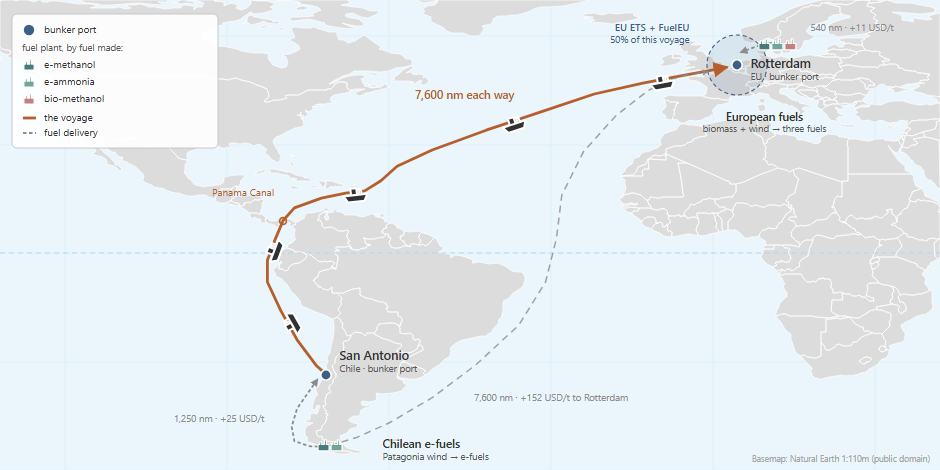)

*San Antonio to Rotterdam via the Panama Canal: the two bunker ports, the
voyage, and the possible fuel plants.*

Read example_4.nav and solved its first year in 2 s: 1 fleet, 4 vessels, 5 fuels, 5 plants, 2 ports, 2 regulations.
The case's own files are in navigate-zcs/docs/notebooks/notebook_1/copper_trade/, the library in navigate-zcs/assumptions/.


In [2]:
# THE CASE: "notebook_1", the copper trade of Session 1, or "notebook_2", the global case of Session 2
CASE = "notebook_1"

read_case(CASE)

---

## STEP 3: Build the simulation

This section is a "fast track" version of the [Tutorials](https://zerocarbonshipping.github.io/navigate-zcs/tutorials/index.html). We recommend working through them first.

<details>
<summary>Summary from the tutorials</summary>

Navigate is a bit like a "drag and drop" model: you pick some components (*nodes*) from the ones available and add them to your simulation (*deck*).

A **node** is one specific component of the model: a fleet, a vessel, a route, a port, a fuel plant, a regulation, and so on. Ready-made components are stored in the assumptions library, in `assumptions/defaults/`, one folder per type of node (`Fleet`, `Vessel`, `Port`, ...).

**Modules** are lists of components that can be added all at once: for example, `Load DefaultFleet` (`assumptions/modules/default_fleet.inc`) adds all 23 fleets of the library.

A **deck** is the input to a Navigate simulation: one `.nav` file plus the `.inc` files it includes. The `.nav` file is a table of contents with two sections: `DEFINE` for the nodes the simulation is made of, and `EVENTS` for the timeline it steps through.

Two commands in the `.nav` file add components to the deck. `Load` adds a ready-made module from the assumptions library, by its name (`Load DefaultCalibration`). `Include` adds one of the deck's own `.inc` files, by its path (`Include "includes/fleet.inc"`). A single node can also be taken from the library with `Import`, or copied under a new name with `Copy`.

In the deck, a node is written as a type (e.g. `Fleet`), a name in quotes (e.g. `"bulk_carrier_80k_dwt"`), and a block of attributes in braces. For example, the `Fleet` node `bulk_carrier_80k_dwt` declares the Panamax bulk carriers, the ships both cases have. An attribute can be a number (`InitialVessels`, the number of ships in the first year), a list of numbers (`InitialSplit`, the share of each vessel type in the first year), or a link to other nodes (`Vessels`, `TradeGrowth`).

</details>

Run the next cell to read the deck's main file first and see how the deck is built for the selected case.

In [3]:
show_case_deck()

# ---- docs/notebooks/notebook_1/copper_trade/example_4.nav ----
# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# EXAMPLE 4 - Panamax fleet, Chile to Rotterdam.

DEFINE {
    Load DefaultModelDefinition

    # ---- fleet ----
    Include "includes/fleet.inc"

    # ---- route ----
    Include "includes/route.inc"
    Include "includes/ports.inc"

    # ---- fuel ----
    Load DefaultSource
    Load DefaultTransport
    Include "includes/fuel_production.inc"
    Include "includes/regions.inc"
    Include "includes/producer.inc"
    Include "includes/fuel_delivery.inc"
    Load DefaultEmission

    # ---- regulation ----
    Include "includes/eu_ets.inc"
    Include "includes/fuel_eu.inc"

    # ---- behavioural traits ----
    Load DefaultCalibration
}

EVENTS {
    Load DefaultTimeStepYearly
}

# ---- docs/notebooks/notebook_1/copper_trade/includes/fleet.inc ----
# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# FLEET - Panamax bulk carriers (~80,000 DWT): the library's fleet for this class.
# It brings the four configurations of one hull, which share hull, propulsion
# curve, cargo capacity and OPEX; today's split between them (99.9% fuel oil,
# 0.1% LNG) and the ships' ages; trade growth; retrofit costs; speed management;
# and the seven efficiency technologies, with the share of today's ships
# already fitted with each.
# Only what makes this one trade rather than the world's fleet is set here.

Import Fleet "bulk_carrier_80k_dwt"

# Imported by name too, so that the Vessel "bulk_carrier_80k_dwt_*" block of
# route.inc matches them: a wildcard block matches only the nodes a deck
# declares, not those its references bring in.
Import Vessel "bulk_carrier_80k_dwt_ice_oil"
Import Vessel "bulk_carrier_80k_dwt_ice_methane"
Import Vessel "bulk_carrier_80k_dwt_ice_methanol"
Import Vessel "bulk_carrier_80k_dwt_ice_ammonia"

Fleet "bulk_carrier_80k_dwt" {
	InitialVessels = 300 # Arbitrary number (represents 8% of the world Panamax fleet)

	# the library's orderbooks are sized for the whole world
	Orderbooks = [0, 0, 0, 0]

	# The library defines no technology-specific rate, so this makes Navigate's
	# own fallback explicit: same value, no warning, nothing invented.
	TechnologyCostOfCapital = Variable("cost_of_capital_vessel")
}

# ---- assumptions/defaults/Fleet/bulk_carrier_80k_dwt.inc ----
# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

Fleet "bulk_carrier_80k_dwt" {

    # vessel types		
	Vessels = [
		Vessel("bulk_carrier_80k_dwt_ice_ammonia"),
		Vessel("bulk_carrier_80k_dwt_ice_methane"),
 		Vessel("bulk_carrier_80k_dwt_ice_methanol"),
		Vessel("bulk_carrier_80k_dwt_ice_oil")
	]
	
	# initial conditions
	InitialVessels = Variable("initial_vessels_bulk_carrier_80k_dwt")
	
	InitialSplit = [
		0.000,
		0.001,
		0.000,
		0.999
	]
	
	InitialAgeDistribution = [
		0,
		Curve("age_dist_bulk_carrier_80k_dwt_methane"),
		0,
		Curve("age_dist_bulk_carrier_80k_dwt_oil")
	]
	
	
	# trade growth
	TradeGrowth = Forecast("trade_growth_bulk_carrier")
	
	# orderbook
	Orderbooks = [
		Forecast("orderbook_bulk_carrier_80k_dwt_ammonia"),
		Forecast("orderbook_bulk_carrier_80k_dwt_methane"),
		Forecast("orderbook_bulk_carrier_80k_dwt_methanol"),
		Forecast("orderbook_bulk_carrier_80k_dwt_oil")
	]

	# technologies
	Technologies = [
		Technology("air_lubrication_bulk_carrier_panamax"),
		Technology("exhaust_gas_boiler_ae_bulk_carrier_panamax"),
		Technology("flettner_rotor_bulk_carrier_panamax"),
		Technology("hull_painting_bulk_carrier_panamax"),
		Technology("lighting_system_bulk_carrier_panamax"),
		Technology("propeller_improvement_devices_bulk_carrier_panamax"),
		Technology("variable_frequency_drive_bulk_carrier_panamax")
	]

	set_initial_technology_share("*", "exhaust_gas_boiler_ae_bulk_carrier_panamax

Nodes refer to each other, forming a nested structure: the `Fleet` lists its `Vessel` nodes, each vessel names its `Tank` nodes (as well as its `Route` and its engines, the `Converter` nodes), and each tank links to the nodes that hold its size, CAPEX and OPEX.

The nested structure ends with a numerical assumption. A numerical assumption is either written in the attribute itself (`InitialVessels = 300`) or held in a "numerical assumption node" that the attribute links to: a `Variable`, `Curve`, `Forecast`, `Surface` or `Timetable` (see STEP 4).

Run the next cell to follow the nested structure, tab by tab: from one of the case's
`Fleet` nodes, `FLEET`, to one of its vessels and its tanks, down to the numbers at the end.
The figures of STEP 4 follow the same fleet. The copper trade has one fleet,
`bulk_carrier_80k_dwt`; the global case has 23, and `bulk_carrier_80k_dwt` is one of them.

In [4]:
# THE FLEET the cells below follow: the copper trade has only bulk_carrier_80k_dwt, the global case 23 fleets
FLEET = "bulk_carrier_80k_dwt"

follow_fleet(FLEET)

The fleet figures follow bulk_carrier_80k_dwt: bulk_carrier_80k_dwt_ice_oil, bulk_carrier_80k_dwt_ice_methane, bulk_carrier_80k_dwt_ice_methanol, bulk_carrier_80k_dwt_ice_ammonia.


# ---- docs/notebooks/notebook_1/copper_trade/includes/fleet.inc ----
# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# FLEET - Panamax bulk carriers (~80,000 DWT): the library's fleet for this class.
# It brings the four configurations of one hull, which share hull, propulsion
# curve, cargo capacity and OPEX; today's split between them (99.9% fuel oil,
# 0.1% LNG) and the ships' ages; trade growth; retrofit costs; speed management;
# and the seven efficiency technologies, with the share of today's ships
# already fitted with each.
# Only what makes this one trade rather than the world's fleet is set here.

Import Fleet "bulk_carrier_80k_dwt"

# Imported by name too, so that the Vessel "bulk_carrier_80k_dwt_*" block of
# route.inc matches them: a wildcard block matches only the nodes a deck
# declares, not those its references bring in.
Import Vessel "bulk_carrier_80k_dwt_ice_oil"
Import Vessel "bulk_carrier_80k_dwt_ice_methane"
Import Vessel "bulk_carrier_80k_dwt_ice_methanol"
Import Vessel "bulk_carrier_80k_dwt_ice_ammonia"

Fleet "bulk_carrier_80k_dwt" {
	InitialVessels = 300 # Arbitrary number (represents 8% of the world Panamax fleet)

	# the library's orderbooks are sized for the whole world
	Orderbooks = [0, 0, 0, 0]

	# The library defines no technology-specific rate, so this makes Navigate's
	# own fallback explicit: same value, no warning, nothing invented.
	TechnologyCostOfCapital = Variable("cost_of_capital_vessel")
}

# ---- assumptions/defaults/Fleet/bulk_carrier_80k_dwt.inc ----
# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

Fleet "bulk_carrier_80k_dwt" {

    # vessel types		
	Vessels = [
		Vessel("bulk_carrier_80k_dwt_ice_ammonia"),
		Vessel("bulk_carrier_80k_dwt_ice_methane"),
 		Vessel("bulk_carrier_80k_dwt_ice_methanol"),
		Vessel("bulk_carrier_80k_dwt_ice_oil")
	]
	
	# initial conditions
	InitialVessels = Variable("initial_vessels_bulk_carrier_80k_dwt")
	
	InitialSplit = [
		0.000,
		0.001,
		0.000,
		0.999
	]
	
	InitialAgeDistribution = [
		0,
		Curve("age_dist_bulk_carrier_80k_dwt_methane"),
		0,
		Curve("age_dist_bulk_carrier_80k_dwt_oil")
	]
	
	
	# trade growth
	TradeGrowth = Forecast("trade_growth_bulk_carrier")
	
	# orderbook
	Orderbooks = [
		Forecast("orderbook_bulk_carrier_80k_dwt_ammonia"),
		Forecast("orderbook_bulk_carrier_80k_dwt_methane"),
		Forecast("orderbook_bulk_carrier_80k_dwt_methanol"),
		Forecast("orderbook_bulk_carrier_80k_dwt_oil")
	]

	# technologies
	Technologies = [
		Technology("air_lubrication_bulk_carrier_panamax"),
		Technology("exhaust_gas_boiler_ae_bulk_carrier_panamax"),
		Technology("flettner_rotor_bulk_carrier_panamax"),
		Technology("hull_painting_bulk_carrier_panamax"),
		Technology("lighting_system_bulk_carrier_panamax"),
		Technology("propeller_improvement_devices_bulk_carrier_panamax"),
		Technology("variable_frequency_drive_bulk_carrier_panamax")
	]

	set_initial_technology_share("*", "exhaust_gas_boiler_ae_bulk_carrier_panamax", Curve("uptake_exhaust_gas_boiler_ae_bulk_carrier_panamax"))
	set_initial_technology_share("*", "hull_painting_bulk_carrier_panamax", Curve("uptake_hull_painting_bulk_carrier_panamax"))
	set_initial_technology_share("*", "lighting_system_bulk_carrier_panamax", Curve("uptake_lighting_system_bulk_carrier_panamax"))
	set_initial_technology_share("*", "propeller_improvement_devices_bulk_carrier_panamax", Curve("uptake_propeller_improvement_devices_bulk_carrier_panamax"))
	set_initial_technology_share("*", "variable_frequency_drive_bulk_carrier_panamax", Curve("uptake_variable_frequency_drive_bulk_carrier_panamax"))

	# fuel conversions
	set_conversion_cost("*ice_oil*", "*ice_methanol*", 17.5e6)
	set_conversion_cost("*ice_oil*", "*ice_ammonia*", 24.1e6)
	set_conversion_cost("*ice_methane*", "*ice_ammonia*", 14.2e6)

	# speed management
	AllowSpeedManagement = TRUE
	MaximumSpeedCha

---

## STEP 4: Explore the input data

### General introduction to Navigate numerical assumptions

Most numerical assumptions in the library are written into a `.inc` file as one
of five node types. A `Variable` is a single number. The other four are lookup
tables, from which the model reads a value when it needs one: a `Curve` is looked
up by one number, a `Forecast` by a date, a `Surface` by two numbers, and a
`Timetable` by a date and a number.

The default numbers in the `assumptions` folder were collected by the Center.
Extended documentation of the underlying assumptions is under development. The
unit of a number depends on the attribute that uses it: the Reference Manual gives
it for each attribute, and many library files also state it in a `# Unit:` line.

<details>
<summary>Using your own numbers instead of the Center's</summary>

To change a number for one simulation, `Import` its node in the deck and reassign
the attributes to change, as Session 2's `levers.inc` does for the fuel prices. To
change the defaults for every simulation, keep your own copy of the `assumptions`
folder and give it to Navigate with `-d` (or `ASSUMPTIONS_DATA_DIR`).

</details>

See the Reference Manual for
[Variable](https://zerocarbonshipping.github.io/navigate-zcs/reference_manual/variable.html),
[Curve](https://zerocarbonshipping.github.io/navigate-zcs/reference_manual/curve.html),
[Forecast](https://zerocarbonshipping.github.io/navigate-zcs/reference_manual/forecast.html),
[Surface](https://zerocarbonshipping.github.io/navigate-zcs/reference_manual/surface.html)
and
[Timetable](https://zerocarbonshipping.github.io/navigate-zcs/reference_manual/timetable.html)
for more details.

Run the next cell to see one node of each of the five types.

In [5]:
show_number_nodes()

# ---- assumptions/defaults/Variable/cost_of_capital_vessel.inc ----
# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# Description: Cost of capital for financing a MF-oil, DF-methane, and DF-methanol vessel.
# Unit: Fraction / year

Variable "cost_of_capital_vessel" {
	Value = 0.0889
}

# ---- assumptions/defaults/Curve/age_dist_bulk_carrier_80k_dwt_methane.inc ----
# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

Curve "age_dist_bulk_carrier_80k_dwt_methane" {
	Table = [
		0,	0;
		1,	1;
		2,	0;
		3,	0;
		4,	0;
		5,	0;
		6,	0;
		7,	0;
		8,	0;
		9,	0;
		10,	0;
		11,	0;
		12,	0;
		13,	0;
		14,	0;
		15,	0;
		16,	0;
		17,	0;
		18,	0;
		19,	0;
		20,	0;
		21,	0;
		22,	0;
		23,	0;
		24,	0;
	]
}

# ---- assumptions/defaults/Forecast/electricity_cost_europe_mid.inc ----
# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# Description: Levelized cost of electricity in Europe (mid case).
# Unit: USD / MWh / year


Forecast "electricity_cost_europe_mid" {
	Table = [
		"01-01-2025",	77.1;
		"01-01-2026",	72.1;
		"01-01-2027",	69.2;
		"01-01-2028",	72.1;
		"01-01-2029",	70.9;
		"01-01-2030",	70.9;
		"01-01-2031",	68.8;
		"01-01-2032",	67.4;
		"01-01-2033",	66.1;
		"01-01-2034",	64.8;
		"01-01-2035",	63.7;
		"01-01-2036",	62.6;
		"01-01-2037",	61.6;
		"01-01-2038",	60.6;
		"01-01-2039",	59.7;
		"01-01-2040",	58.8;
		"01-01-2041",	57.9;
		"01-01-2042",	57.1;
		"01-01-2043",	56.4;
		"01-01-2044",	55.8;
		"01-01-2045",	55.2;
		"01-01-2046",	54.6;
		"01-01-2047",	54.0;
		"01-01-2048",	53.5;
		"01-01-2049",	53.2;
		"01-01-2050",	52.7;
	]
	
	Extrapolate = LINEAR
}

# ---- assumptions/defaults/Surface/bulk_carrier_80k_dwt_propulsion_load.inc ----
# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

Surface "bulk_carrier_80k_dwt_propulsion_load" {
	Table = [		 
				0,		 1;
		 6.5,	0.78,	 1.25;
		 7.5,	1.08,	 1.71;
		 8.5,	1.44,	 2.28;
		 9.5,	1.87,	 2.97;
		10.5,	2.39,	 3.79;
		11.5,	3.04,	 4.82;
		12.5,	3.84,	 6.09;
		13.5,	4.85,	 7.70;
		14.5,	6.21,	 9.85;
		15.5,	7.76,	12.31;
	]
}

# ---- assumptions/defaults/Timetable/methanol_synthesis_electro_capex.inc ----
# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# Description: Capital expenditure of e-methanol synthesis.
# Unit: USD / ton

Timetable "methanol_synthesis_electro_capex" {
	Table = [
        	            25,      50,  	100, 	250, 	500, 	1000,	1500,	2000,	2500,	3000,	3500,	4000,	4500,	5000,	5500;
        "01-01-2025",	4374,	3302,	2492,	1718,	1297,	979,	    830, 	739, 	675, 	627, 	589, 	558, 	532, 	509, 	490;
        "01-01-2050",	4374,	3302,	2492,	1718,	1297,	979,	    830, 	739, 	675, 	627, 	589, 	558, 	532, 	509, 	490;
	]
	
	Extrapolate = LINEAR
}

### Exploring the input data specific to the case

The rest of this part checks the numbers that drive this case, in four groups:

1. **Fleet**: what the ships cost to build and to retrofit, and the efficiency technologies
   on offer
2. **Fuels**: the price of the fossil fuels and of electricity, what each alternative
   fuel costs to make, how much feedstock is available, and what it costs to ship a
   fuel from the plant to the bunker port
3. **Regulations**: the prices and limits each regulation sets, its penalty, and what each
   regulation counts
4. **Behavioural traits**: how sharply the owners react to a difference in cost or value, and the producers
   to a difference in demand or cost, and how much of last year's choices the owners, the producers and the
   operators repeat

Every number below is read from the deck the case cell read.

<details>
<summary>Finding the numbers the tabs do not show</summary>

The folded tabs at the end of each section show a few of the numbers behind its figures. Every other number is in a file you can open from
Colab's file browser: click the folder icon in the left sidebar and open `navigate-zcs` (running locally, it is in
the `ROOT` folder of STEP 1). Double-click a file to read it beside the notebook.

Two folders hold the inputs, both named by the STEP 2 cell:

- **The case's own folder**, under `docs/notebooks/`: the `.nav` file and the files it names with `Include`, in
  `includes/`. An attribute set there replaces the library's value for that node. A file the `.nav` file does not
  `Include` is not part of this run (the levers' files, for example, are used only by the session's sensitivity
  runs).
- **The assumptions library**, `assumptions/`: `modules/` holds the lists that `Load` adds (`Load DefaultFleet`
  reads `modules/default_fleet.inc`), and `defaults/` holds one file per node, in a folder named after the node
  type, the file named after the node: `Forecast("electricity_cost_europe_mid")` is in
  `assumptions/defaults/Forecast/electricity_cost_europe_mid.inc`.

To find a number, follow the links as STEP 3 did: open the file of the node that uses it, find the attribute, and
open the node it names, until you reach the number. Look in the case's own folder first, since what is set there
replaces the library's value.

</details>

---

### 1. Data about the fleet

The most important data that will affect how the fleet ends up being designed are:
- the ship retrofitting costs from one fuel to another
- the CAPEX of newbuild ships and their financing conditions
- the efficiency technology on offer, and what it costs

The fleet design also depends on the composition of the initial fleet (`InitialVessels`, `InitialSplit` and `InitialAgeDistribution`), the efficiency technology already installed, how fast the trade grows (`TradeGrowth`), when ships are scrapped (`Lifetime`, `FixedScrapRate`), and the ship orderbook (`Orderbooks`, the ships already ordered but not yet delivered).


#### Newbuild CAPEX, retrofitting costs and financing conditions
Running the next cell shows some of our assumptions on ship retrofitting costs, the CAPEX of newbuild ships and the cost of capital each configuration is financed at.

A newbuild is charged in four parts, which the charter rate carries: the vessel's own `Capex`, here the hull plus the fuel supply system (fuel handling and safety), the engines (each `Converter` priced per MW installed) and the tanks (each `Tank` priced per m3 of containment).

In [6]:
def draw_ship_costs():
    # what each of the fleet's vessels costs to build, by part, and what each retrofit costs; the parts are
    # those the charter rate carries: the vessel's own CAPEX (its hull and its fuel supply system), its engines
    # (each converter priced per MW) and its tanks (priced per m3), read at the start date
    fleet = case["fleet"]
    parts = {"hull": [], "supply system": [], "engines": [], "tanks": []}
    for vessel in case["vessels"]:
        terms = references(vessel.capex)
        supply = sum(value(case["nodes"].forecasts[name]) for kind, name in terms if "supply_system" in name)
        parts["hull"].append(value(vessel.capex) - supply)
        parts["supply system"].append(supply)
        parts["engines"].append(sum(value(c.capex) * value(c.power_capacity) for c in vessel.get_converters()))
        parts["tanks"].append(sum(value(t.capex) * value(t.volume) for t in vessel.tanks))
    names = [short(v.name) for v in case["vessels"]]
    newbuild = go.Figure()
    for (part, costs), colour in zip(parts.items(), (GREY, YELLOW, BLUE, GREEN)):
        newbuild.add_bar(x=names, y=np.array(costs) / 1e6, name=part, marker_color=colour,
                         hovertemplate="%{x}: %{y:.1f} M USD<extra>" + part + "</extra>")
    totals = np.sum(list(parts.values()), axis=0) / 1e6
    newbuild.add_scatter(x=names, y=totals, mode="text", text=[f"{t:.1f}" for t in totals], textposition="top center",
                         showlegend=False, hoverinfo="skip")
    newbuild.update_layout(barmode="stack", height=380, legend_traceorder="normal")
    newbuild.update_yaxes(title_text="M USD", rangemode="tozero")

    pairs = [(a, b, cost) for (a, b), cost in fleet.conversion_costs.items() if cost is not None and a != b]
    retrofit = go.Figure(go.Bar(x=[f"{short(a)} → {short(b)}" for a, b, _ in pairs],
                                y=[value(cost) / 1e6 for *_, cost in pairs], marker_color=BLUE,
                                text=[f"{value(cost) / 1e6:.1f}" for *_, cost in pairs], textposition="outside",
                                hovertemplate="%{x}: %{y:.1f} M USD<extra></extra>"))
    retrofit.update_layout(height=380)
    retrofit.update_yaxes(title_text="M USD", rangemode="tozero")
    show_figures((f"Newbuild: what each of the fleet's ships costs, by part ({str(case['start'])[:4]})", newbuild, 420),
                 ("Retrofit: what converting an existing ship costs", retrofit, 300))
    year = str(case["start"])[:4]
    show_table(pd.DataFrame({f"cost of capital in {year}": [f"{value(v.cost_of_capital):.1%}" for v in case["vessels"]],
                             "in 2050": [f"{value(v.cost_of_capital, case['years'][-1]):.1%}" for v in case["vessels"]],
                             "lifetime (years)": [f"{value(v.lifetime):.0f}" for v in case["vessels"]]}, index=names),
               "Show cost of capital and ship lifetime", folded=True)


draw_ship_costs()

,cost of capital in 2026,in 2050,lifetime (years)
ice oil,8.9%,8.9%,25
ice methane,8.9%,8.9%,25
ice methanol,8.9%,8.9%,25
ice ammonia,11.1%,8.9%,25


Notes

- The cargo space lost to larger fuel tanks is deliberately not included in the base assumptions: with an optimised ship design it can be reduced to a negligible amount.

- The ammonia ship is financed at a higher cost of capital in the early years, because of the higher risk.

#### Efficiency technology on offer, and what is already fitted

The assumptions library carries seven efficiency measures for each vessel
class, each with its own cost and saving. The fleet starts with a share of its
ships already carrying each technology (`set_initial_technology_share`).

In [7]:
def technology_class(name):
    # the vessel class a technology's name ends with, such as _bulk_carrier_panamax
    names = [t.name for t in case["fleet"].technologies]
    common = names[0]
    for other in names[1:]:
        while not other.endswith(common):
            common = common[1:]
    return "_" + common.split("_", 1)[1] if "_" in common else common


def draw_technology():
    # the efficiency measures the fleet may fit, cheapest first, and the share of today's ships already carrying
    # each; a share is set by the ship's age, so the figure reads it for each age the fleet's ships have today
    fleet = case["fleet"]
    technologies = sorted(fleet.technologies, key=lambda t: t.capex.get(0))
    rows = []
    for t in technologies:
        saves = ", ".join(f"{value(s):.1%} of {kind.name.lower()}" for kind, s in t.energy_savings.items() if value(s))
        power = ", ".join(f"{value(p):g} MW of {kind.name.lower()}" for kind, p in t.external_power.items() if value(p))
        rows.append({"measure": label(t.name.removesuffix(technology_class(t.name))),
                     "saves": saves or power + " supplied from outside",
                     "CAPEX (USD)": f"{value(t.capex):,.0f}", "OPEX (USD/yr)": f"{value(t.opex):,.0f}",
                     "life (yr)": f"{value(t.lifetime):.0f}" if t.lifetime is not None else ""})
    # the ships most of today's fleet is: the largest initial split
    vessel = fleet.vessels[int(np.argmax([value(share) for share in fleet.initial_split]))]
    names, shares, notes = [], [], []
    for t in technologies:
        share = fleet.initial_technology_shares[(vessel.name, t.name)]
        by_age = [value(share, age) if share is not None else 0.0 for age in range(26)]
        names.append(label(t.name.removesuffix(technology_class(t.name))))
        shares.append(by_age[0] * 100)
        same = max(by_age) - min(by_age) < 1e-9
        notes.append(f"{by_age[0]:.0%}" if same else f"{by_age[0]:.0%} of new ships, {by_age[-1]:.0%} at 25 years")
    plot = go.Figure(go.Bar(y=names, x=shares, orientation="h", marker_color=[GREEN if x else GREY for x in shares],
                            text=[note if x else "none fitted" for note, x in zip(notes, shares)],
                            textposition="outside", hoverinfo="skip"))
    plot.update_layout(height=60 + 34 * len(names))
    plot.update_xaxes(title_text="% of today's ships already carrying it", range=[0, 100])
    plot.update_yaxes(autorange="reversed")
    show_figures((f"Already on board before the model decides anything ({short(vessel.name)} ships)", plot, 600))
    show_table(pd.DataFrame(rows).set_index("measure"), "The efficiency measures on offer, cheapest first "
               "(no life: it stays until the ship leaves the fleet)",
               folded="Show the cost of the different efficiency measures")


draw_technology()

,saves,CAPEX (USD),OPEX (USD/yr),life (yr)
measure,,,,
exhaust gas boiler ae,5.0% of heat,"100,000","10,000",
lighting system,2.5% of electrical,"100,000",0,
variable frequency drive,10.0% of electrical,"100,000","5,000",
propeller improvement devices,2.0% of propulsion,"150,000",0,
hull painting,5.0% of propulsion,"200,000","24,000",5
air lubrication,4.0% of propulsion,"1,500,000","20,000",25
flettner rotor,0.4 MW of propulsion supplied from outside,"2,000,000","40,000",


In [8]:
show_files("fleet")

# ---- assumptions/defaults/Forecast/bulk_carrier_80k_dwt_capex.inc ----
# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

Forecast "bulk_carrier_80k_dwt_capex" {
	Table = [
		"01-01-2025",	42.4e6;
		"01-01-2050",	42.4e6;
	]
}

# ---- assumptions/defaults/Forecast/bulk_carrier_80k_dwt_supply_system_methane_capex.inc ----
# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

Forecast "bulk_carrier_80k_dwt_supply_system_methane_capex" {
	Table = [
		"01-01-2025",	4.37e6;
		"01-01-2050",	4.37e6;
	]
}

# ---- assumptions/defaults/Variable/cost_of_capital_vessel.inc ----
# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# Description: Cost of capital for financing a MF-oil, DF-methane, and DF-methanol vessel.
# Unit: Fraction / year

Variable "cost_of_capital_vessel" {
	Value = 0.0889
}

# ---- assumptions/defaults/Technology/exhaust_gas_boiler_ae_bulk_carrier_panamax.inc ----
# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

Technology "exhaust_gas_boiler_ae_bulk_carrier_panamax" {
	set_energy_saving(HEAT, 0.05)
	
	Capex = 100e3
	Opex = 10e3
}

# ---- assumptions/defaults/Technology/lighting_system_bulk_carrier_panamax.inc ----
# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

Technology "lighting_system_bulk_carrier_panamax" {
	set_energy_saving(ELECTRICAL, 0.025)
	
	Capex = 1e5
	Opex = 0.
}

# ---- assumptions/defaults/Technology/propeller_improvement_devices_bulk_carrier_panamax.inc ----
# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

Technology "propeller_improvement_devices_bulk_carrier_panamax" {
	set_energy_saving(PROPULSION, 0.02)
	
	Capex = 150e3
	Opex = 0.
}

# ---- assumptions/defaults/Technology/flettner_rotor_bulk_carrier_panamax.inc ----
# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

Technology "flettner_rotor_bulk_carrier_panamax" {
	set_external_power(PROPULSION, 0.4)
	
	Capex = 2e6
	Opex = 40e3
}

Also, laid out the same way: variable_frequency_drive_bulk_carrier_panamax, hull_painting_bulk_carrier_panamax, air_lubrication_bulk_carrier_panamax, in assumptions/defaults/Technology/

---

### 2. Data about the fuels

The most important data related to fuels are:
- the market price of the fuels bought on a liquid market, such as fuel oil and LNG
- the cost of making each alternative fuel: the plant, the electricity and the feedstock it uses
- how much feedstock there is, which limits how much of a fuel can be made (not its price)
- what it costs to deliver a fuel to the bunker port, and the port's handling cost

The supply also depends on each plant's cost of capital, lead time, lifetime and uptime, and on how much a port can deliver (`set_bunkering_limit`).

In both cases, we assume that fossil fuels (fuel oil and LNG) have a flat price until 2050.

Electricity is the largest part of what an e-fuel costs to make. It is assumed that its cost decreases in the future.

In [9]:
def draw_prices():
    # the market price of the fuels the ports sell at a quoted price, and the cost of electricity in each region,
    # drawn by Lantern
    nodes = case["nodes"]
    port = next(iter(nodes.ports.values()))
    fossil = lantern_figure([("", fuel, price) for fuel, price in port.fuel_prices.items()
                             if price is not None], "USD/t")
    electricity = lantern_figure([("", region.name, region.source_opex["renewable"])
                                  for region in nodes.regions.values()], "USD/MWh")
    show_figures(("What it has to beat: fossil bunker prices", fossil, 380),
                 ("The main input to an e-fuel: electricity", electricity, 380))


draw_prices()

The synthesis and electrolyser cost tables are currently assumed to be flat over time. Learning rates (costs falling as more capacity is built) may be added in a future version of Navigate.

A step's CAPEX and fixed OPEX are paid on its capacity, in USD per ton/year it can make, whatever the share of the year the plant runs (its `Uptime`): a plant that runs less spreads them over fewer tons.

For bio-methanol, the CAPEX is a forecast that falls over time, and is the same per ton/year of capacity whatever the plant's size.

Run the next cell to see what each step costs to build and run, what each production step needs, per ton of what it makes, and what each feedstock costs.

In [10]:
# the steps of the e-methanol and e-ammonia chains, and bio-methanol's, as the figures name them
STEPS = {"electrolysis_stack_alkaline": "electrolyser stack", "hydrogen_electro_alkaline": "hydrogen plant",
         "methanol_synthesis_electro_alkaline": "e-methanol synthesis",
         "ammonia_synthesis_electro_alkaline": "e-ammonia synthesis",
         "methanol_synthesis_bio_gasification": "bio-methanol synthesis"}


def draw_production():
    # what each production step needs per ton of what it makes, and what it costs to build and run by its size
    nodes, region = case["nodes"], production_region()
    steps = [step for step in STEPS if step in nodes.processes and step in region.process_capex]
    rows = []
    for step in steps:
        process = nodes.processes[step]
        inputs = ", ".join(f"{value(amount):.2f} t {STEPS.get(feed.name) or label(feed.name)}"
                           for feed, amount in zip(process.feeds, process.conversions))
        lifetime = region.process_lifetimes.get(step)
        rows.append({"step": STEPS[step], "inputs per ton of output": inputs,
                     "electricity (MWh/t)": value(region.process_energy[step]),
                     "life (yr)": value(lifetime) if lifetime is not None else "the plant's"})

    capex, opex = go.Figure(), go.Figure()
    tables = [region.process_capex[step] for step in steps if type(region.process_capex[step]).__name__ == "Timetable"]
    smallest, largest = min(table.y.min() for table in tables), max(table.y.max() for table in tables)
    for step, colour in zip(steps, STYLE.palette):
        for plot, table in ((capex, region.process_capex[step]), (opex, region.process_opex[step])):
            if type(table).__name__ == "Timetable":  # looked up by date and size
                sizes = np.geomspace(table.y.min(), table.y.max(), 200)
                plot.add_scatter(x=sizes, y=[table.get(0.0, size) for size in sizes], name=STEPS[step],
                                 mode="lines", line={"color": colour, "width": 2}, legendgroup=step,
                                 showlegend=plot is capex)
            else:  # looked up by date only: the same at any size
                plot.add_scatter(x=[smallest, largest], y=[value(table)] * 2, name=STEPS[step] + " (any size)",
                                 mode="lines", line={"color": colour, "width": 2, "dash": "dash"}, legendgroup=step,
                                 showlegend=plot is capex)
    for plot, title in ((capex, "USD per t/yr of capacity"), (opex, "USD/yr per t/yr of capacity")):
        plot.update_layout(height=400)
        plot.update_xaxes(type="log", title_text="capacity of the step (t of output per day)")
        plot.update_yaxes(title_text=title, rangemode="tozero")
    show_figures((f"CAPEX falls with the plant's size ({str(case['start'])[:4]})", capex, 380),
                 ("and so does fixed OPEX", opex, 380))
    show_table(pd.DataFrame(rows).set_index("step"), f"What each step needs ({label(region.name)})", folded=True)
    feedstocks = {label(name): value(cost) for name, cost in region.feedstock_costs.items() if cost is not None}
    show_table(pd.DataFrame({"USD/t at the start": feedstocks}), "What each feedstock costs", folded=True)


draw_production()

,inputs per ton of output,electricity (MWh/t),life (yr)
step,,,
electrolyser stack,10.00 t demineralized water,51.00,10.00
hydrogen plant,1.00 t electrolyser stack,4.00,20.00
e-methanol synthesis,"0.19 t hydrogen plant, 1.40 t carbon dioxide biogenic",1.55,the plant's
e-ammonia synthesis,"0.18 t hydrogen plant, 0.82 t nitrogen air separation",0.44,the plant's
bio-methanol synthesis,2.42 t feedstock biomethanol gasification,0.52,the plant's


,USD/t at the start
carbon dioxide biogenic,150.00
feedstock biomethanol gasification,65.00
demineralized water,2.00


#### Feedstock availability

The availability of a fuel made from biomass or biogenic CO2 is limited by its feedstock supply.
For example, bio-methanol needs gasifiable biomass, and e-methanol needs biogenic CO2.

Each cap is set on the producer that makes the fuel, with `set_feed_limit`.

The cell below shows how much of each feedstock is available in this case.

In [11]:
def draw_feedstock():
    # each feedstock ceiling of the case: how much of it shipping may use each year, a panel each, drawn by Lantern
    constraints = [(feed, limit) for producer in case["nodes"].producers.values()
                   for feed, limit in producer.feed_limits.items() if limit is not None]
    plot = lantern_figure([(feed, feed, limit) for feed, limit in constraints], "t/year")
    plot.update_layout(showlegend=False)
    show_figures(("How much of each feedstock shipping may use", plot, 300 * len(constraints)))


draw_feedstock()

#### Delivering the fuel to the bunker ports

Shipping a fuel from its plant to the bunker port adds to its cost (`set_fuel_distance` on the `Plant`, at the
rate its region sets with `set_transport_cost`), so fuel is cheap at the port next door and carries a penalty
at the far one.

In [12]:
def draw_delivery():
    # what shipping a fuel from its plant's region to each bunker port adds to its cost
    nodes = case["nodes"]
    trips = {}
    for plant in nodes.plants.values():
        for port, delivery in plant.fuel_deliveries.items():
            if delivery:
                transport, distance = delivery
                rate = value(plant.region.transport_costs[transport.name])
                trips[(plant.region.name, port)] = (value(distance), value(distance) * rate, rate)
    if not trips:
        print("No plant in this case sets a delivery trip (set_fuel_distance): a fuel reaches every port "
              "at its production cost, plus the port's handling cost.")
        return
    plot = go.Figure()
    for port, colour in zip(nodes.ports, (BLUE, YELLOW, GREEN, PEACH)):
        regions = [region for region, to in trips if to == port]
        plot.add_bar(x=[label(r) for r in regions], y=[trips[(r, port)][1] for r in regions], name=f"to {label(port)}",
                     marker_color=colour, text=[f"{trips[(r, port)][0]:,.0f} nm" for r in regions],
                     textposition="outside",
                     hovertemplate="%{y:.0f} USD/t<extra>" + label(port) + "</extra>")
    rate = next(iter(trips.values()))[2]
    plot.update_layout(height=360, barmode="group")
    plot.update_xaxes(title_text="where the fuel is made")
    plot.update_yaxes(title_text="USD per ton of fuel", rangemode="tozero")
    show_figures((f"Fuel pays {rate:g} USD per ton per nautical mile to reach the bunker port", plot, 500))


draw_delivery()

In [13]:
show_files("fuels")

# ---- assumptions/defaults/Forecast/fossil_fuel_oil_price_global.inc ----
# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# Description: Forecast of the global fossil fuel oil price.
# Unit: USD / ton

Forecast "fossil_fuel_oil_price_global" {
	Table = [
		"01-01-2026",	485;
		"01-01-2050",	485;
	]

	Extrapolate = FLAT
}

# ---- assumptions/defaults/Forecast/liquefied_natural_gas_price_global.inc ----
# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# Description: Cost of liquefied natural gas (LNG) in Middle East
# Unit: USD / ton

Forecast "liquefied_natural_gas_price_global" {
	Table = [
		"01-01-2026",	436;
		"01-01-2050",	436;
	]

	Extrapolate = FLAT
}

# ---- assumptions/defaults/Forecast/electricity_cost_americas_mid.inc ----
# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# Description: Levelized cost of electricity in Americas (mid case).
# Unit: USD / MWh / year


Forecast "electricity_cost_americas_mid" {
	Table = [
		"01-01-2025",	76.0;
		"01-01-2026",	61.8;
		"01-01-2027",	58.9;
		"01-01-2028",	55.1;
		"01-01-2029",	53.0;
		"01-01-2030",	50.9;
		"01-01-2031",	48.7;
		"01-01-2032",	47.2;
		"01-01-2033",	45.7;
		"01-01-2034",	44.2;
		"01-01-2035",	46.6;
		"01-01-2036",	46.0;
		"01-01-2037",	45.6;
		"01-01-2038",	45.4;
		"01-01-2039",	45.1;
		"01-01-2040",	44.5;
		"01-01-2041",	44.3;
		"01-01-2042",	44.0;
		"01-01-2043",	43.9;
		"01-01-2044",	43.5;
		"01-01-2045",	43.1;
		"01-01-2046",	42.8;
		"01-01-2047",	42.4;
		"01-01-2048",	41.9;
		"01-01-2049",	41.6;
		"01-01-2050",	41.2;
	]
	
	Extrapolate = LINEAR
}

Also, laid out the same way: electricity_cost_europe_mid
# ---- assumptions/defaults/Timetable/methanol_synthesis_electro_capex.inc ----
# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# Description: Capital expenditure of e-methanol synthesis.
# Unit: USD / ton

Timetable "methanol_synthesis_electro_capex" {
	Table = [
        	            25,      50,  	100, 	250, 	500, 	1000,	1500,	2000,	2500,	3000,	3500,	4000,	4500,	5000,	5500;
        "01-01-2025",	4374,	3302,	2492,	1718,	1297,	979,	    830, 	739, 	675, 	627, 	589, 	558, 	532, 	509, 	490;
        "01-01-2050",	4374,	3302,	2492,	1718,	1297,	979,	    830, 	739, 	675, 	627, 	589, 	558, 	532, 	509, 	490;
	]
	
	Extrapolate = LINEAR
}

Also, laid out the same way: the other steps' Timetables, named in the region's file
# ---- docs/notebooks/notebook_1/copper_trade/includes/producer.inc ----
# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# PRODUCERS - the agents that decide whether to build another plant.

Producer "producer_efuel" {
	Plants = [Plant("plant_methanol_electro_alkaline_americas"),
	          Plant("plant_ammonia_electro_alkaline_americas"),
	          Plant("plant_methanol_electro_alkaline_europe"),
	          Plant("plant_ammonia_electro_alkaline_europe")]

	MaximumDevelopment = <Forecast("epc_global_capacity_mid") * Forecast("epc_global_share_shipping")>

	# Ceiling on biogenic CO2, the feedstock both its e-methanol plants draw on.

	set_feed_limit("carbon_dioxide_biogenic", <Forecast("carbon_dioxide_biogenic_availability_flat") * Forecast("carbon_dioxide_biogenic_share_shipping") * Variable("trade_share_biogenic_carbon_dioxide")>)
}

Producer "producer_biofuel" {
	Plants = [Plant("plant_methanol_bio_gasification_europe")]

	MaximumDevelopment = <Forecast("epc_global_capacity_mid") * Forecast("epc_global_share_shipping")>

	# Ceiling on gasifiable biomass.
	set_feed_limit("feedstock_biomethanol_gasification", <Forecast("feedstock_biomethanol_gasification_availability") * Forecast("feedstock_biomethanol_gasification_share_shipping") * Variable

---

### 3. Data about the regulations

The most important data about a regulation are:
- the **price** it puts on emissions, for a scheme that prices them
- the **limit** it sets, for a scheme that caps the intensity of the fuel
- the **penalty** for missing that limit
- its **scope**: which emissions it counts, with its own emission factors
- **how much of the voyage** it counts: which ports are inside the scheme

<details>
<summary>What else a regulation sets</summary>

Besides these, a regulation sets which ships it covers (`set_include_vessel`), whether it applies ship by ship or across the fleet (`Scheme`), and the global warming potentials it uses.

</details>

Navigate has two kinds of policy node. A `Regulation` sets a yearly target on emissions or emission intensity, with a penalty for missing it. A `Levy` charges a fuel, or subsidises it, per ton of emissions. In both cases, the EU instruments are `Regulation` nodes, as in the library: FuelEU Maritime caps intensity, and the EU ETS prices every ton counted (a target of zero tons, with the allowance price as the penalty). The global case adds a global fuel standard (`gfs`), an intensity limit with a penalty, as FuelEU, on every voyage.

The two instruments work differently:

| | FuelEU Maritime | EU ETS |
|:---|:---|:---|
| **What it measures** | the **intensity** of the energy used, gCO2eq/MJ | the **quantity** emitted, tons CO2eq |
| **What you pay** | a penalty on how far you miss the annual target | a price on every covered ton |
| **Emissions counted** | **well-to-wake**: how the fuel was made counts | **tank-to-wake**: only what the ship burns on board |

The EU ETS allowance price and each intensity limit are Forecasts, plotted below, and the FuelEU penalty is a single `Variable`. The scope is explained under "What each regulation actually counts" below, and how much of the voyage is counted in the next paragraph.

The ports inside a scheme are its `Jurisdiction`, and the coverage
fractions are applied leg by leg (a *leg* is a ship's one-way sailing from one port to the next): `IntraFraction` for a leg with both ends inside, `InterFraction` for one end inside, `ExtraFraction` for neither; a stay in a port inside is counted in full. On the route of the fleet's ships that gives:

In [14]:
def show_coverage():
    # how much of each leg and each port stay of the fleet's route each regulation counts
    route = case["fleet"].vessels[0].route
    rows = {}
    for regulation in case["nodes"].regulations.values():
        counted = regulation.expectation
        for (start, end), fraction in counted.leg_fraction.items():
            if (start, end) in route.get_leg_keys():
                rows.setdefault(f"leg {label(start)} → {label(end)}", {})[label(regulation.name)] = f"{fraction[0]:.0%}"
        for port in route.distinct_ports:
            rows.setdefault(f"stay in {label(port.name)}", {})[label(regulation.name)] = (
                f"{counted.port_fraction[port.name][0]:.0%}")
    show_table(pd.DataFrame(rows).T, f"What each regulation counts of the route {route.name}")


show_coverage()

,EU ETS,FuelEU
leg San Antonio → Rotterdam,50%,50%
leg Rotterdam → San Antonio,50%,50%
stay in San Antonio,0%,0%
stay in Rotterdam,100%,100%


In [15]:
def draw_regulation_levels():
    # what each regulation charges for a ton missed or emitted, and the intensity limit of those that set one,
    # for the fleet's ships, drawn by Lantern
    regulations = case["nodes"].regulations
    vessel = case["fleet"].vessels[0].name
    prices = lantern_figure([("", r.name, r.remedial_cost) for r in regulations.values()], "USD/tCO2eq", regulations)
    limits = lantern_figure([("", r.name, r.vessel_thresholds[vessel]) for r in regulations.values()
                             if r.measure == RegulationMeasureID.INTENSITY], "gCO2eq/MJ", regulations)
    show_figures(("The price of a ton: emitted (EU ETS) or above the limit (penalty)", prices, 380),
                 ("The intensity limits (lower is stricter)", limits, 380))


draw_regulation_levels()

**What to look for:** When does each regulation's pressure arrive: early as a price, or late as a limit? How does a missed limit's penalty compare with the ETS price?

#### What each regulation actually counts

What a ship emits and what a regulation counts are two different numbers. Navigate's
results, such as the well-to-wake emission curves, show what a ship emits, **as Navigate estimates it**:
the fuel's own emission factors, with each engine's methane slip, plus what making
and delivering the fuel emitted, weighted with the library's warming potentials. A
regulation counts the same fuel by its own rules, and that count only sets what the
owners pay.

<details>
<summary>Five ways what a regulation counts differs from Navigate's estimate</summary>

1. **Its own emission factors**: `set_fuel_ttw` and `set_fuel_wtt` in the regulation's
   file replace Navigate's own, which are used only where the regulation
   states none. That is how the EU ETS counts no combustion CO2 for bio- and e-fuels.
2. **Its scope**: the EU ETS counts only what is burned on board (TTW), FuelEU also
   how the fuel was made (WTW).
3. **Its own warming potentials**: the EU ETS weights methane 28 and nitrous oxide
   265, FuelEU 25 and 298, set in each regulation file; the results use the
   library's, 29.8 for methane over 100 years.
4. **Its geography**: only the legs and port stays of the table above are counted,
   by the share it gives. The figure below shows each fuel per MJ, before this is
   applied.
5. **Its phase-in**: the EU ETS brings methane and nitrous oxide in through a
   phase-in (`eu_ets_ghg_phase_in`). It is complete from 2026, so in both cases they
   count in full from the first year.

</details>

The graph below shows what each regulation counts for each fuel the fleet's ships can burn and, in its last
panel, Navigate's estimate of the emissions.

A hatched bar is a credit upstream: the fuel's carbon was taken from the air or from biomass, so its WTT is negative and removes part of what is burned on board.

In [16]:
# the fuels from fossil to the alternatives, by molecule
FUEL_ORDER = ["fossil_fuel_oil", "liquefied_natural_gas", "methane_bio", "methane_electro", "methanol_bio",
              "methanol_electro", "ethanol_bio", "fatty_acid_methyl_ester", "diesel_electro", "ammonia_blue",
              "ammonia_electro"]


def lhv(fuel):
    return value(case["nodes"].fuels[fuel].lower_heating_value)  # GJ/t


def counted(regulation, fuel, vessel, engine):
    # what a regulation counts for a fuel burned in the ship's main engine, in its first year, as gCO2eq/MJ with the
    # regulation's own warming potentials: (TTW, WTT or None where its scope leaves WTT out, where the WTT comes from)
    expectation = regulation.expectation
    ttw = sum(expectation.ttw_consumption[(vessel.name, engine.name, fuel, emission.name)][0]
              + expectation.ttw_slip[(vessel.name, engine.name, fuel, emission.name)][0]
              for emission in regulation.emissions)
    if regulation.scope == PolicyScopeID.TTW:
        return ttw / lhv(fuel) * 1e3, None, None
    wtt = sum(expectation.wtt[(vessel.name, fuel, emission.name)][0] for emission in regulation.emissions)
    stated = any(regulation.fuel_wtt.get((fuel, emission.name)) is not None for emission in regulation.emissions)
    return ttw / lhv(fuel) * 1e3, wtt / lhv(fuel) * 1e3, "stated in the regulation" if stated else "Navigate's own"


def estimated(fuel, vessel, engine):
    # what burning a fuel emits as Navigate estimates it, with the library's warming potentials: TTW the fuel burned
    # in the ship's main engine, slip included; WTT its plants' production and delivery to the route's ports, or,
    # for a fuel no plant makes, the figure the ports apply
    nodes = case["nodes"]
    plants = [plant for plant in nodes.plants.values() if plant.fuel.name == fuel]
    ports = [port.name for port in vessel.route.distinct_ports]
    ttw = wtt = 0.0
    for emission in nodes.emissions.values():
        gwp = value(emission.gwp, case["lifetime"])
        key = (engine.name, fuel, emission.name)
        ttw += (vessel.expectation.ttw_consumption[key] + vessel.expectation.ttw_slip[key]) * gwp
        if plants:
            upstream = np.mean([plant.expectation.production_wtt[emission.name][0]
                                + plant.expectation.delivery_wtt[(port, emission.name)][0]
                                for plant in plants for port in ports])
        else:
            upstream = np.nanmean([nodes.ports[port].expectation.fuel_wtt[(fuel, emission.name)][0]
                                   for port in ports])
        wtt += np.nan_to_num(upstream) * gwp
    return float(ttw) / lhv(fuel) * 1e3, float(wtt) / lhv(fuel) * 1e3, "Navigate's own"


def draw_regulation_counts():
    # what each regulation counts for each fuel the fleet's ships may burn, per MJ, and Navigate's own estimate:
    # TTW what is burned on board, WTT what making and delivering the fuel emitted
    fleet, nodes = case["fleet"], case["nodes"]
    burners = {}  # each fuel, the fleet's ship and main engine that burns it
    for vessel in fleet.vessels:
        engine = vessel.propulsion_converter
        for fuel in nodes.fuels.values():
            if fuel.fuel_type in engine.main_fuel_types:
                burners.setdefault(fuel.name, (vessel, engine))
    fuels = sorted(burners, key=lambda fuel: FUEL_ORDER.index(fuel) if fuel in FUEL_ORDER else len(FUEL_ORDER))
    panels = [(regulation.name, f"{label(regulation.name)} counts ({regulation.scope.name})")
              for regulation in nodes.regulations.values()] + [(None, "Navigate's estimate (WTW)")]
    plot = make_subplots(rows=1, cols=len(panels), shared_yaxes=True, subplot_titles=[title for _, title in panels],
                         horizontal_spacing=0.03)
    shown = set()
    for col, (name, _) in enumerate(panels, start=1):
        for row, fuel in enumerate(fuels):
            ttw, wtt, source = (counted(nodes.regulations[name], fuel, *burners[fuel]) if name
                                else estimated(fuel, *burners[fuel]))
            bars = [("TTW: burned on board", 0, ttw, BLUE, "")]
            if wtt is not None and wtt >= 0:
                bars.append((f"WTT: {source}", ttw, wtt, GREEN if source == "Navigate's own" else YELLOW, ""))
            elif wtt is not None:  # a credit upstream eats into what is burned: what is left solid counts
                bars = [("TTW: burned on board", 0, ttw + wtt, BLUE, ""),
                        (f"WTT: {source}, removed upstream", ttw + wtt, -wtt,
                         GREEN if source == "Navigate's own" else YELLOW, "/")]
            for legend, base, width, colour, pattern in bars:
                plot.add_bar(y=[label(fuel)], x=[width], base=[base], orientation="h", name=legend,
                             marker={"color": colour, "pattern": {"shape": pattern}}, legendgroup=legend,
                             showlegend=legend not in shown, hovertemplate=f"{legend}: %{{x:.0f}} gCO2eq/MJ<extra></extra>",
                             row=1, col=col)
                shown.add(legend)
            total = ttw + (wtt or 0)
            plot.add_annotation(x=max(ttw, total), y=label(fuel), text=f"<b>{round(total) or 0:.0f}</b>", showarrow=False,
                                xanchor="left", xshift=4, row=1, col=col)
        if name and nodes.regulations[name].measure == RegulationMeasureID.INTENSITY:
            limit = value(nodes.regulations[name].vessel_thresholds[fleet.vessels[0].name])
            plot.add_vline(x=limit, line={"color": GREY, "dash": "dash", "width": 1}, row=1, col=col,
                           annotation_text=f"limit {limit:.0f}", annotation_position="bottom right")
    plot.update_layout(barmode="overlay", height=120 + 44 * len(fuels))
    plot.update_xaxes(title_text="gCO2eq/MJ", range=[0, 130])
    plot.update_yaxes(autorange="reversed")
    show_figures((f"What each regulation counts for each fuel, in {str(case['start'])[:4]}", plot, 1000))


draw_regulation_counts()

**What to look for:** For bio-methanol, how much does the EU ETS count, and how much FuelEU? Where does the gap come from? Which regulation scores bio-methanol better against fuel oil?

In [17]:
show_files("regulations")

# ---- assumptions/defaults/Forecast/eu_ets_carbon_credit_price.inc ----
# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# Description: Price of carbon credits under the EU ETS regulation.
# Unit: USD / ton

Forecast "eu_ets_carbon_credit_price" {
	Table = [
		"01-01-2024",	100;
		"01-01-2025",	119;
		"01-01-2030",	155;
		"01-01-2035",	198;
		"01-01-2040",	252;
		"01-01-2045",	325;
		"01-01-2050",	417;
	]
	
	Extrapolate = LINEAR
}

# ---- assumptions/defaults/Forecast/eu_ets_maritime_phase_in.inc ----
# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# Description: The percentage of emissions the maritime industry will be required to pay for under the EU ETS regulation.
# Unit: Fraction

Forecast "eu_ets_maritime_phase_in" {
	Table = [
		"01-01-2024",	0.4;
		"01-01-2025",	0.7;
		"01-01-2026",	1;
		"01-01-2050",	1;
	]
	
	Extrapolate = FLAT
}

# ---- assumptions/defaults/Variable/fuel_eu_remedial_cost.inc ----
# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# Description: The remedial cost of exceeding the GFI target of the FuelEU Maritime regulation.
# Unit: USD/ton

Variable "fuel_eu_remedial_cost" {
    Value = 760
}

# ---- assumptions/defaults/Forecast/fuel_eu_target_reduction.inc ----
# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# Description: The GFI targets of the FuelEU Maritime regulation.
# Unit: gCO2eq/MJ

Forecast "fuel_eu_target_reduction" {
	Table = [
		"01-01-2022",	1.0;
		"01-01-2025",	0.98;
		"01-01-2030",	0.94;
		"01-01-2035",	0.855;
		"01-01-2040",	0.69;
		"01-01-2045",	0.38;
		"01-01-2050",	0.20;
	]
	
	Multiplier = 91.16		# baseline value from FuelEU
	Extrapolate = FLAT
	Interpolate = PREVIOUS
}

# ---- assumptions/defaults/Variable/eu_default_diesel_carbon_dioxide.inc ----
# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# Description: Default carbon dioxide emissions emitted per ton of diesel consumed in a diesel-injection internal combustion engine under the EU ETS and FuelEU Maritime regulation.
# Unit: ton methane / ton fuel

Variable "eu_default_diesel_carbon_dioxide" {
    Value = 3.114
}

# ---- assumptions/defaults/Variable/eu_default_diesel_ice_methane.inc ----
# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# Description: Default methane emissions emitted per ton of fuel consumed in a diesel-injection internal combustion engine under the EU ETS and FuelEU Maritime regulation.
# Unit: ton methane / ton fuel

Variable "eu_default_diesel_ice_methane" {
    Value = 0.00005
}

Also, laid out the same way: 9 more emission factors, named in each regulation's file in assumptions/defaults/Regulation/

---

### 4. Data about behavioural traits

The most important data about how the owners and the producers decide are:
- the **decision sensitivities**: how sharply the owners respond to a cost difference, and the producers to a difference in expected demand or cost
- the three **inertias**: the owners, the producers and the operators (when bunkering) each repeat part of the previous year's choices, as much as the inertia says

<details>
<summary>What else bounds the decisions</summary>

Besides these, the decisions are bounded by limits: how often a ship can be retrofitted (`RetrofitInterval`), how far the operators may change speed (`MaximumSpeedChange`) and how fast the producers can build (`MaximumDevelopment`).

</details>

In both cases, the sensitivities and the inertias come from `Load DefaultCalibration`. It sets all three inertias to 0: each year's choices start afresh.

Each sensitivity says how strongly the owners favour the cheaper option. The
fleet stands for many owners who face the same costs but do not all decide
alike, so a choice comes out as shares spread across them. A value close to 1
means they hardly care about cost and their choices stay evenly spread. A value
far from 1 means nearly all of them pick the cheapest.

<details>
<summary>The formulas: fuel type sensitivity (newbuild and retrofit)</summary>

For the choice of fuel type for a newbuild ship, with $c_i$ the levelised cost per cargo-mile of a new ship of fuel type $i$, $s_i$ its share of the newbuilds and $S$ the value of
`FuelSensitivity`:

$$
\frac{s_i}{s_j} = \left(\frac{c_i}{c_j}\right)^{-\beta},
\qquad \beta = -\frac{\ln S}{\ln 1.1}
$$

Retrofits work the same way, but on NPV rather than cost. When a ship reaches a
retrofit cycle, each possible conversion is weighed against keeping the ship as
it is. With $\mathrm{NPV}_i$ the net present value of conversion $i$ (the fuel and compliance savings over the ship's remaining life, minus the conversion cost), CAPEX the capital cost of a new ship of its type and $S$ the value of `ConversionSensitivity`:

$$
\frac{s_i}{s_\mathrm{keep}} = e^{\beta \, \mathrm{NPV}_i / \mathrm{CAPEX}},
\qquad \beta = \frac{\ln S}{0.05}
$$

</details>

The figure below draws both formulas for a choice between two options. The bold
line is the deck's value, and the dashed lines show less and more decisive owners.

In [18]:
def draw_sensitivities():
    # the two formulas of the owners' choices, drawn for a choice between two options: the share one option gets
    # as its gap to the other grows. The fleet's value in bold, less and more decisive owners dashed.
    fleet = case["fleet"]
    inter_fuel, conversion = value(fleet.fuel_sensitivity), value(fleet.conversion_sensitivity)

    def by_cost(gap, odds):
        return 1 / (1 + (1 + gap) ** (-np.log(odds) / np.log(1.1)))

    def by_npv(npv, odds):
        return 1 / (1 + np.exp(-np.log(odds) / 0.05 * npv))

    plots = []
    for share, deck, others, x, point, title, axis, note in (
            (by_cost, inter_fuel, (0.9, 0.5), np.linspace(-0.3, 0.3, 121), 0.10,
             "Choosing a fuel type: FuelSensitivity", "how much more this fuel type costs than the other",
             "10 % dearer: {:.0%} of the newbuilds"),
            (by_npv, conversion, (1.5, 4), np.linspace(-0.15, 0.15, 121), 0.05,
             "Retrofitting a ship: ConversionSensitivity", "NPV of the conversion, as a share of the ship's CAPEX",
             "NPV worth 5 % of CAPEX: {:.0%} convert")):
        plot = go.Figure()
        for odds, kind in zip(others, ("less decisive", "more decisive")):
            plot.add_scatter(x=x, y=share(x, odds), mode="lines", name=f"{odds:g} ({kind})",
                             line={"color": GREY, "width": 1.5, "dash": "dash"})
        plot.add_scatter(x=x, y=share(x, deck), mode="lines", name=f"{deck:g} (the deck)",
                         line={"color": BLUE, "width": 3})
        plot.add_scatter(x=[point], y=[share(point, deck)], mode="markers+text", showlegend=False,
                         marker={"color": BLUE, "size": 9}, text=[note.format(share(point, deck))],
                         textposition="bottom left")
        plot.update_layout(height=360)
        plot.update_xaxes(title_text=axis, tickformat="+.0%")
        plot.update_yaxes(title_text="share", tickformat=".0%", range=[0, 1])
        plots.append((title, plot, 380))
    show_figures(*plots)


draw_sensitivities()

The producers choose their plants the same way, in two steps: the year's build is
first shared between fuels by expected demand (the `Producer`'s `FuelSensitivity`), then each
fuel's share is split between the plants that make it, by delivered cost
(`VariantSensitivity`). [Session 4](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/workshop-colab/docs/workshop/04-how-navigate-solves.ipynb) shows both steps at work, in
"Stage 3 — The producers decide too".

<details>
<summary>The formulas: fuel demand sensitivity and fuel cost sensitivity</summary>

First, the year's
build is shared between fuels by demand. With $D_i$ the expected unmet demand for
fuel $i$ over a plant's lifetime, discounted so the first years count most, $s_i$
its share of the build and $S$ the value of the `Producer`'s `FuelSensitivity`:

$$
\frac{s_i}{s_j} = \left(\frac{D_i}{D_j}\right)^{\beta},
\qquad \beta = \frac{\ln S}{\ln 1.1}
$$

With the default calibration's 1.25, a fuel with 10 % more expected demand gets 1.25 times the
odds. Then each fuel's share is split between the plants that make it, by cost.
With $c_p$ the levelised cost of the fuel that plant $p$ delivers to the ports, $s_p$
its share and $S$ the value of `VariantSensitivity`:

$$
\frac{s_p}{s_q} = \left(\frac{c_p}{c_q}\right)^{-\beta},
\qquad \beta = -\frac{\ln S}{\ln 1.1}
$$

</details>

In [19]:
show_files("decisions")

# ---- assumptions/modules/default_calibration.inc ----
# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

Port "*" {
	set_bunkering_inertia("*", 0.0)
}

# Fleet decision-process calibration.
#
# Each sensitivity is an odds ratio against a fixed reference change. For the cost-based choices
# (lower-is-better levelized cost of transport) a value below 1 penalizes a 10% higher cost; for the
# NPV-based choices (higher-is-better) a value above 1 rewards an NPV advantage equal to 5% of the
# summed ship Capex. A value of 1 means no preference.
Fleet "*" {
	Inertia = 0.0
	FuelSensitivity = 0.75         # a 10% higher cost gives 25% lower odds of a fuel type
	VariantSensitivity = 0.75         # a 10% higher cost gives 25% lower odds of a technology variant
	ConversionSensitivity = 2       # an NPV advantage of 5% of ship Capex doubles the odds
	TechnologySensitivity = 2           # an NPV advantage of 5% of ship Capex doubles the odds
}

# Producer decision-process calibration.
#
# FuelSensitivity is higher-is-better (odds for a 10% higher expected demand); VariantSensitivity
# is lower-is-better (odds for a 10% higher levelized cost of fuel). A value of 1 means no preference.
Producer "*" {
	Inertia = 0.0
	FuelSensitivity = 1.25        # a 10% higher expected demand gives 1.25x the odds of a pathway
	VariantSensitivity = 0.75          # a 10% higher LCoF gives 25% lower odds of a plant
}

## Workshop sessions

**Next: [Session 4: How Navigate solves](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/workshop-colab/docs/workshop/04-how-navigate-solves.ipynb)**

Each link opens the notebook in Google Colab, in a fresh session, so run it
from the top.

1. [Run a simple case](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/dev/docs/notebooks/notebook_1/notebook_1.ipynb)
2. [Run a global case](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/dev/docs/notebooks/notebook_2/notebook_2.ipynb)
3. **How a Navigate model is built** (this session)
4. [How Navigate solves](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/workshop-colab/docs/workshop/04-how-navigate-solves.ipynb)
5. [Build your own case](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/workshop-colab/docs/workshop/05-build-your-own-case.ipynb)